# CWRU bearing signals: from raw vibration to a fault frequency, what a split does to the score, and which lightweight model generalises

**Data:** public CWRU bearing data, 12 kHz drive-end channel, faults of 0.007, 0.014 and 0.021 in, four loads (0 to 3 HP).

**Questions:**
1. Can classical signal processing recover the fault frequency predicted by bearing geometry?
2. How much of a model's score survives when the test data comes from conditions it never saw?
3. Among lightweight classifiers from different families (linear, instance-based, kernel, trees, neural nets), which one generalises best, and at what cost?

**Roadmap**

| § | Section | What it answers |
|---|---|---|
| 1 | Setup | Imports, plotting style, data download |
| 2 | The dataset | What is actually in the subset: files, durations, windows, measured speed |
| 3 | From raw vibration to a fault frequency | Q1: spectrum, spectrogram, spectral kurtosis, envelope analysis, speed effects |
| 4 | Features and what they encode | Time statistics vs envelope physics features; how much each one tracks the recording rather than the fault |
| 5 | What the split does to the score | Q2: one random forest under three test protocols |
| 6 | Lightweight classifiers across model families | Q3: seven models, same folds, accuracy and deployment cost |
| 7 | Conclusions and limitations | |

Code cells are collapsed; expand any cell to see it.

## 1. Setup

In [1]:
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import signal
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import balanced_accuracy_score, confusion_matrix, f1_score, recall_score
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler

import bearings as b
import models

warnings.filterwarnings("ignore", category=UserWarning)
BLUE, ORANGE, AQUA, PURPLE = "#2a78d6", "#eb6834", "#1baf7a", "#8a5cd1"
CLASS_COLORS = dict(zip(b.CLASSES, (BLUE, ORANGE, AQUA, PURPLE)))
INK, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.size": 10, "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 11, "axes.titlelocation": "left", "lines.linewidth": 1.2,
})

Path("results").mkdir(exist_ok=True)
b.download()
ORDERS = b.fault_orders()

## 2. The dataset

The subset uses one bearing (SKF 6205, drive end) per fault type and size, each recorded at four motor loads. Recordings are cut into non-overlapping 1 s windows (12 000 samples), which become the samples for every model in §5 and §6.

Most files also store the **measured** shaft speed (`XnnnRPM`). I use it wherever it exists and fall back to the nominal speed for the load (two healthy files have no speed field).

In [2]:
rows = []
for (label, damage), numbers in b.FILES.items():
    for load, n in enumerate(numbers):
        x = b.read(n)
        rows.append(dict(label=label, damage=damage, load=load, file=n, seconds=round(len(x) / b.FS, 1),
                         windows=len(x) // b.FS, rpm_measured=b.rpm(n), rpm_nominal=round(b.SHAFT_HZ[load] * 60)))
inventory = pd.DataFrame(rows)
windows_table = inventory.pivot_table(index=["label", "damage"], columns="load", values="windows", aggfunc="sum")
windows_table.columns = [f"{c} HP" for c in windows_table.columns]
windows_table["total"] = windows_table.sum(axis=1)
print("1 s windows per recording (rows: class and fault size, columns: load)")
display(windows_table.reindex(b.CLASSES, level=0))

speed = inventory.pivot_table(index="load", values=["rpm_nominal", "rpm_measured"], aggfunc=["min", "max"])
speed.columns = [f"{s} {a}" for a, s in speed.columns]
print("Shaft speed per load across all recordings (rpm)")
speed[["rpm_nominal min", "rpm_measured min", "rpm_measured max"]].rename(columns={"rpm_nominal min": "nominal"})

1 s windows per recording (rows: class and fault size, columns: load)


0 HP  1 HP  2 HP  3 HP  total
label      damage                               
Normal     0.000     20    40    40    40    140
Inner race 0.007     10    10    10    10     40
           0.014     10    10    10    10     40
           0.021     10    10    10    10     40
Outer race 0.007     10    10    10    10     40
           0.014     10    10    10    10     40
           0.021     10    10    10    10     40
Ball       0.007     10    10    10    10     40
           0.014     10    10    10    10     40
           0.021     10    10    10    10     40

Shaft speed per load across all recordings (rpm)


,nominal,rpm_measured min,rpm_measured max
load,,,
0,1797,1796.0,1797.0
1,1772,1771.0,1774.0
2,1750,1748.0,1754.0
3,1730,1721.0,1729.0


- **Small data:** 40 recordings, 500 windows. Each faulty recording gives ~10 windows, so windows are highly correlated within a recording.
- **One healthy bearing:** the 140 Normal windows all come from the same bearing, in longer recordings (20 to 40 s). "Normal" is therefore easy to recognise in every protocol and says little about healthy-bearing variability.
- **Speed varies by a few rpm across recordings at the same load** and differs from the nominal speed by up to ~10 rpm. At BPFI (5.4× shaft speed) that is about 1 Hz, which is the size of the frequency resolution of a 1 s window.

## 3. From raw vibration to a fault frequency

My research used raw signals with learned features, so here I work through the classical chain by hand.

### Why a bearing fault is hard to see

A local defect produces a short impact each time a rolling element passes it. Each impact rings a structural resonance, usually at kilohertz, and the repetition rate is the fault frequency, usually at a few hundred hertz or less. So the useful information is an **amplitude modulation of a high-frequency carrier**. The raw spectrum shows the carrier and the shaft harmonics, and the repetition rate is mostly hidden.

Bearing geometry predicts the repetition rates:

In [3]:
pd.DataFrame({"order (x shaft speed)": ORDERS, "Hz at 1797 rpm": {k: v * b.SHAFT_HZ[0] for k, v in ORDERS.items()}}).round(3)

,order (x shaft speed),Hz at 1797 rpm
BPFO,3.585,107.364
BPFI,5.415,162.186
BSF,2.357,70.584
FTF,0.398,11.929


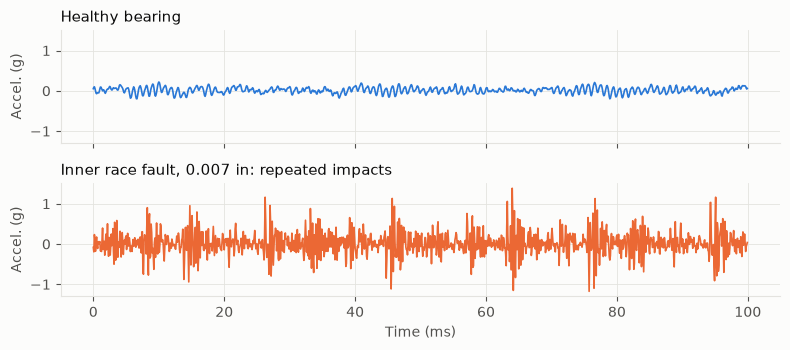

In [4]:
normal, inner, outer = b.read(97), b.read(105), b.read(130)
t = np.arange(b.FS // 10) / b.FS * 1000
fig, axes = plt.subplots(2, 1, figsize=(8, 3.6), sharex=True, sharey=True)
axes[0].plot(t, normal[:len(t)], color=BLUE); axes[0].set_title("Healthy bearing")
axes[1].plot(t, inner[:len(t)], color=ORANGE); axes[1].set_title("Inner race fault, 0.007 in: repeated impacts")
axes[1].set_xlabel("Time (ms)")
for a in axes: a.set_ylabel("Accel. (g)")
fig.tight_layout()
plt.show()

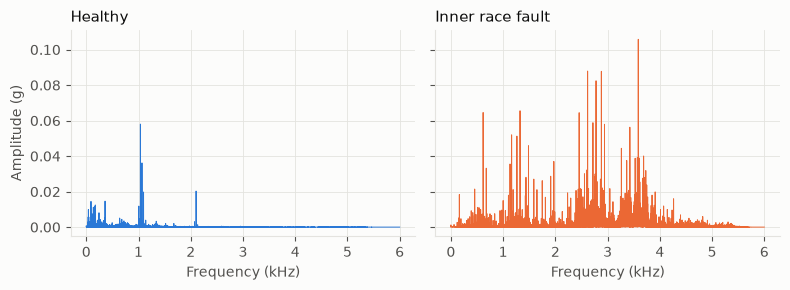

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3), sharey=True)
for a, x, name, c in ((axes[0], normal, "Healthy", BLUE), (axes[1], inner, "Inner race fault", ORANGE)):
    f, X = b.spectrum(x)
    a.plot(f / 1000, X, color=c, linewidth=0.7); a.set_title(name); a.set_xlabel("Frequency (kHz)")
axes[0].set_ylabel("Amplitude (g)")
fig.tight_layout()
plt.show()

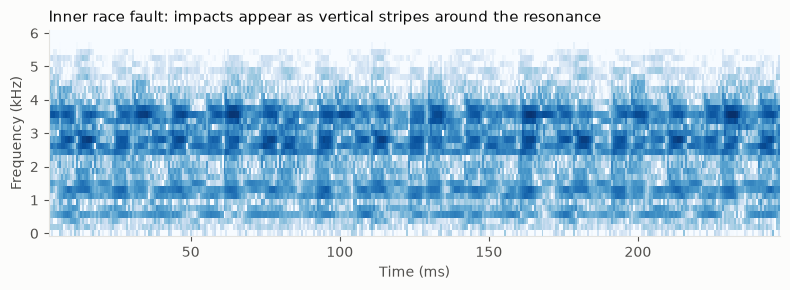

In [6]:
fig, a = plt.subplots(figsize=(8, 3))
seg = inner[:b.FS // 4]
f, tt, S = signal.spectrogram(seg, fs=b.FS, nperseg=64, noverlap=56)
a.pcolormesh(tt * 1000, f / 1000, 10 * np.log10(S + 1e-12), cmap="Blues", shading="auto", vmin=-70)
a.grid(False); a.set_xlabel("Time (ms)"); a.set_ylabel("Frequency (kHz)")
a.set_title("Inner race fault: impacts appear as vertical stripes around the resonance")
fig.tight_layout()
plt.show()

### Choosing the band with spectral kurtosis

Kurtosis measures how impulsive a band is. The window length matters: it has to be shorter than the gap between impacts. At the inner race fault frequency that gap is about 6 ms, so a 256-sample window (21 ms) already blends several impacts.

In [7]:
rows = []
for n, name in ((97, "Healthy"), (105, "Inner race 0.007"), (130, "Outer race 0.007"), (118, "Ball 0.007")):
    sk = b.spectral_kurtosis(b.read(n))
    sk = sk[(sk.f > 200) & (sk.f < 5800)]
    for w, g in sk.groupby("window"):
        rows.append({"signal": name, "window (samples)": w, "max SK": round(g.sk.max(), 2), "at Hz": int(g.f[g.sk.idxmax()])})
pd.DataFrame(rows).pivot(index="signal", columns="window (samples)", values=["max SK", "at Hz"])

max SK                           at Hz                  \
window (samples)   64    128   256   512   1024    64      128     256    
signal                                                                    
Ball 0.007         0.26  0.34  0.41  0.19  0.31  2625.0  3281.0  3281.0   
Healthy            0.29  0.45  1.14  1.82  0.55  4875.0  2531.0  3046.0   
Inner race 0.007   1.42  1.25  0.48  0.25  0.31  4500.0  4500.0  4546.0   
Outer race 0.007   2.92  1.90  0.48  0.30  0.22  5250.0  5437.0  5390.0   

                                  
window (samples)    512     1024  
signal                            
Ball 0.007        3281.0  1582.0  
Healthy           3023.0  3023.0  
Inner race 0.007  2835.0  3960.0  
Outer race 0.007   632.0  4699.0

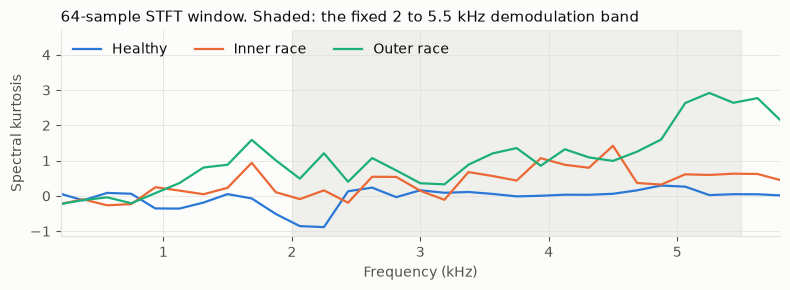

In [8]:
fig, a = plt.subplots(figsize=(8, 3))
for n, name, c in ((97, "Healthy", BLUE), (105, "Inner race", ORANGE), (130, "Outer race", AQUA)):
    sk = b.spectral_kurtosis(b.read(n), stft_windows=(64,))
    a.plot(sk.f / 1000, sk.sk, color=c, label=name, linewidth=1.6)
a.set_xlim(0.2, 5.8); a.set_xlabel("Frequency (kHz)"); a.set_ylabel("Spectral kurtosis")
a.axvspan(2, 5.5, color=GRID, alpha=0.5, zorder=0); a.legend(frameon=False, ncol=3, loc="upper left")
a.set_title("64-sample STFT window. Shaded: the fixed 2 to 5.5 kHz demodulation band")
fig.tight_layout()
plt.show()

With 64-sample windows both race faults peak in the 4.5 to 5.3 kHz region and the healthy signal stays flat. The healthy signal does rise near 3 kHz at long windows (up to 1.82), so a high value alone is not proof of a fault: the window has to match the impact spacing. The ball fault barely registers, which the next section confirms. I keep a **fixed 2 to 5.5 kHz band** for all later steps, chosen before looking at classification results, so the band cannot leak test information into the features.

### Envelope analysis: does the peak land where geometry says?

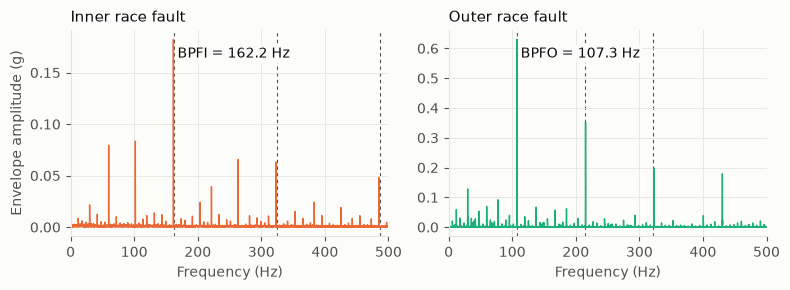

In [9]:
def envelope_panel(a, n, order_name, load, color, title):
    f, E = b.envelope_spectrum(b.read(n))
    target = ORDERS[order_name] * b.shaft_hz(n, load)
    a.plot(f, E, color=color, linewidth=1)
    for h in (1, 2, 3):
        a.axvline(h * target, color=MUTED, linestyle=(0, (3, 3)), linewidth=0.8, zorder=0)
    a.set_xlim(0, 500); a.set_title(title); a.set_xlabel("Frequency (Hz)")
    a.text(target + 6, a.get_ylim()[1] * 0.86, f"{order_name} = {target:.1f} Hz", color=INK,
           bbox=dict(facecolor=SURFACE, edgecolor="none", pad=1.5))

fig, axes = plt.subplots(1, 2, figsize=(8, 3))
envelope_panel(axes[0], 105, "BPFI", 0, ORANGE, "Inner race fault")
envelope_panel(axes[1], 130, "BPFO", 0, AQUA, "Outer race fault")
axes[0].set_ylabel("Envelope amplitude (g)")
fig.tight_layout()
plt.show()

The two race faults show sharp peaks at the predicted frequency and its harmonics. The ball fault is the hard case: a ball spins and rolls, so the defect hits the races only part of the time, with a modulation at the cage frequency (FTF). Below, the same view for ball faults (BSF and harmonics marked; 2×BSF is often stronger because the defect strikes both races once per spin).

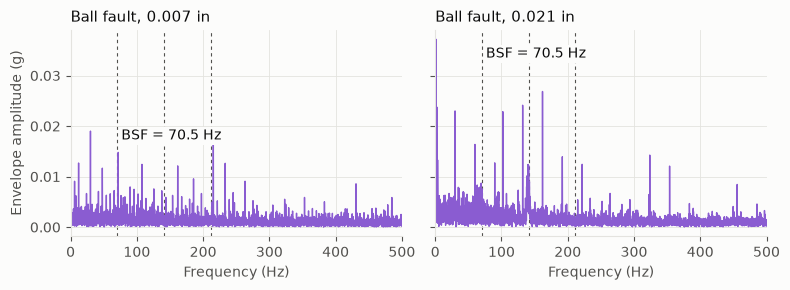

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3), sharey=True)
envelope_panel(axes[0], 118, "BSF", 0, PURPLE, "Ball fault, 0.007 in")
envelope_panel(axes[1], 222, "BSF", 0, PURPLE, "Ball fault, 0.021 in")
axes[0].set_ylabel("Envelope amplitude (g)")
fig.tight_layout()
plt.show()

No clean BSF comb: the 0.007 in record has a line near BSF, but it is no stronger than many lines that are not BSF harmonics, and the 0.021 in record shows nothing at the BSF markers. That is the physical reason ball faults are the hardest class later on.

### Speed: measured vs nominal

Fault frequencies scale with shaft speed. The table checks, for every inner race recording, how far the strongest envelope peak near BPFI lands from the prediction made with the nominal and with the measured speed.

In [11]:
rows = []
for (label, damage), numbers in b.FILES.items():
    if label != "Inner race":
        continue
    for load, n in enumerate(numbers):
        f, E = b.envelope_spectrum(b.read(n))
        nominal, measured = ORDERS["BPFI"] * b.SHAFT_HZ[load], ORDERS["BPFI"] * b.shaft_hz(n, load)
        near = (f > nominal * 0.95) & (f < nominal * 1.05)
        peak = f[near][np.argmax(E[near])]
        rows.append(dict(damage=damage, load=load, file=n, peak_Hz=peak,
                         error_nominal_Hz=peak - nominal, error_measured_Hz=peak - measured))
speed_check = pd.DataFrame(rows)
display(speed_check.round(2).set_index(["damage", "load"]).T)
speed_check[["error_nominal_Hz", "error_measured_Hz"]].abs().agg(["mean", "max"]).round(2)

damage               0.01                                                  \
load                    0       1       2       3       0       1       2   
file               105.00  106.00  107.00  108.00  169.00  170.00  171.00   
peak_Hz            161.70  159.55  157.40  154.93  162.01  160.04  158.07   
error_nominal_Hz    -0.49   -0.38   -0.55   -1.21   -0.18    0.11    0.12   
error_measured_Hz   -0.49   -0.38   -0.37   -0.39   -0.09   -0.07   -0.06   

damage                       0.02                          
load                    3       0       1       2       3  
file               172.00  209.00  210.00  211.00  212.00  
peak_Hz            155.89  161.82  159.83  157.77  155.62  
error_nominal_Hz    -0.25   -0.37   -0.10   -0.17   -0.52  
error_measured_Hz   -0.07   -0.37   -0.28   -0.35   -0.34

,error_nominal_Hz,error_measured_Hz
mean,0.37,0.27
max,1.21,0.49


Using the measured speed lowers the mean error from 0.37 to 0.27 Hz and the worst case from 1.21 to 0.49 Hz (file 108, 3 HP, where the measured speed is 9 rpm below nominal). A small negative offset remains in every file; it is below the 1 Hz resolution of a 1 s window.

### How visible is each fault?

In [12]:
rows = []
for (label, damage), numbers in b.FILES.items():
    if label == "Normal":
        continue
    name = {"Inner race": "BPFI", "Outer race": "BPFO", "Ball": "BSF"}[label]
    for load, n in enumerate(numbers):
        rows.append(dict(label=label, damage=damage, load=load, ratio=b.peak_ratio(b.read(n), ORDERS[name], b.shaft_hz(n, load))))
visibility = pd.DataFrame(rows).pivot_table(index="label", columns="damage", values="ratio", aggfunc="median").round(1)
visibility.to_csv("results/peak_visibility.csv")

for n, name in ((105, "BPFI"), (130, "BPFO")):
    f, E = b.envelope_spectrum(b.read(n))
    target = ORDERS[name] * b.shaft_hz(n, 0)
    band = (f > 10) & (f < 500)
    print(f"file {n}: expected {name} {target:.1f} Hz, strongest envelope peak {f[band][np.argmax(E[band])]:.1f} Hz")
visibility

file 105: expected BPFI 162.2 Hz, strongest envelope peak 161.7 Hz
file 130: expected BPFO 107.3 Hz, strongest envelope peak 107.6 Hz


damage,0.007,0.014,0.021
label,,,
Ball,11.2,4.2,7.9
Inner race,254.5,93.0,153.9
Outer race,777.3,5.9,145.9


Median peak-to-floor ratio at the expected fault frequency, across the four loads. Two things stand out. Ball faults are weak at every size. And **outer race at 0.014 in has almost no visible BPFO**, so fault size does not map monotonically to signal strength in this dataset. Smith and Randall (MSSP, 2015) also found that many CWRU records, ball faults in particular, lack a clear signature. A model cannot generalize to a signature that is not in the data.

Speed also shifts these frequencies: from 0 to 3 HP the shaft slows from 1797 to 1730 rpm, so BPFI moves about 3.7%. From here on I use the measured speed stored in each file (nominal when missing). A real deployment still needs a tachometer or order tracking, since speed is not constant inside a recording either.

---
## 4. Features and what they encode

Every 1 s window is described by two hand-crafted feature sets:

- **Time statistics** (8): RMS, peak, crest factor, kurtosis, skewness, standard deviation, shape factor, impulse factor. Cheap and generic, but sensitive to absolute vibration level.
- **Envelope physics** (9): log peak-to-floor ratio in the envelope spectrum at the 1st to 3rd harmonics of BPFO, BPFI and BSF, computed at each recording's measured speed. Level-independent and tied to bearing geometry.

In [13]:
X, meta = b.windows()
time_f = pd.DataFrame([b.time_features(x) for x in X])
phys_f = pd.DataFrame([b.physics_features(x, hz) for x, hz in zip(X, meta["shaft_hz"])])
FEATURES = {"Time statistics": time_f, "Envelope physics": phys_f, "Both": pd.concat([time_f, phys_f], axis=1)}
y = meta["label"].values
is_normal = (meta["label"] == "Normal").values
print(len(y), "windows;", meta.groupby("label").size().to_dict(), "|", FEATURES["Both"].shape[1], "features")

500 windows; {'Ball': 120, 'Inner race': 120, 'Normal': 140, 'Outer race': 120} | 17 features


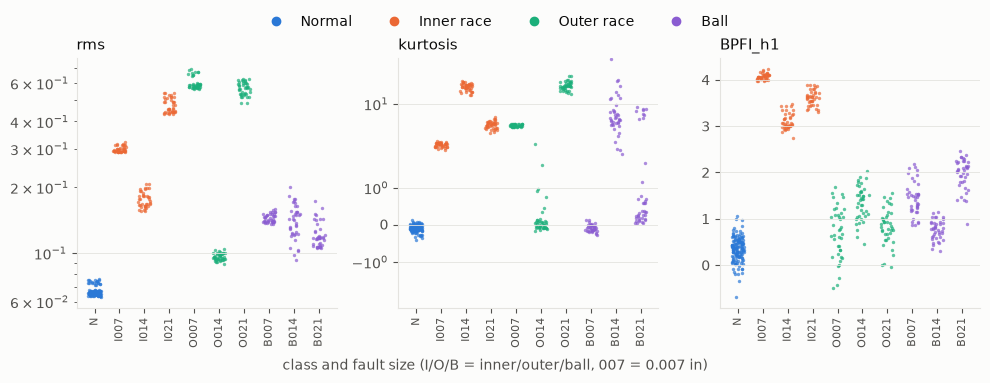

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3.4))
groups = [(label, d) for (label, d) in b.FILES]
groups = sorted(groups, key=lambda g: (b.CLASSES.index(g[0]), g[1]))
rng = np.random.default_rng(0)
for a, feature, log in zip(axes, ("rms", "kurtosis", "BPFI_h1"), (True, True, False)):
    for i, (label, d) in enumerate(groups):
        A = FEATURES["Both"]
        v = A.loc[(meta["label"] == label) & (meta["damage"] == d), feature]
        a.scatter(i + rng.uniform(-0.25, 0.25, len(v)), v, s=6, color=CLASS_COLORS[label], alpha=0.7, linewidths=0)
    a.set_xticks(range(len(groups)), ["N" if l == "Normal" else f"{l.split()[0][0]}{int(d * 1000):03d}" for l, d in groups],
                 rotation=90, fontsize=8)
    if log:
        a.set_yscale("symlog" if feature == "kurtosis" else "log")
    a.set_title(feature); a.grid(axis="x", visible=False)
handles = [plt.Line2D([], [], marker="o", linestyle="", color=c, label=l) for l, c in CLASS_COLORS.items()]
fig.legend(handles=handles, frameon=False, ncol=4, loc="upper center", bbox_to_anchor=(0.5, 1.06))
fig.text(0.5, -0.02, "class and fault size (I/O/B = inner/outer/ball, 007 = 0.007 in)", ha="center", color=MUTED)
fig.tight_layout()
plt.show()

Within a class, RMS and kurtosis change more between fault sizes than between classes: the 0.014 and 0.021 in faults are not "more of" the 0.007 in fault, they are different recordings with different levels. The envelope feature at BPFI separates inner race faults from the rest at every size, but with a level that also depends on the recording.

To quantify this, the table below gives the share of each feature's variance explained by the **class** and by the **recording** (η², between-group variance over total variance). A feature with η²(recording) close to 1 but much lower η²(class) is a recording fingerprint: it lets a model recognise *which file* a window came from, which works under a random split and fails on a new bearing.

In [15]:
def eta_squared(v, groups):
    return v.groupby(groups).transform("mean").var() / v.var()

A = FEATURES["Both"]
eta = pd.DataFrame({
    "set": ["Time statistics"] * time_f.shape[1] + ["Envelope physics"] * phys_f.shape[1],
    "η² class": [eta_squared(A[c], meta["label"]) for c in A],
    "η² recording": [eta_squared(A[c], meta["file"]) for c in A],
}, index=A.columns)
eta["fingerprint gap"] = eta["η² recording"] - eta["η² class"]
display(eta.groupby("set")[["η² class", "η² recording", "fingerprint gap"]].mean().round(2))
eta.sort_values("fingerprint gap", ascending=False).round(2)

,η² class,η² recording,fingerprint gap
set,,,
Envelope physics,0.54,0.91,0.37
Time statistics,0.42,0.94,0.51


,set,η² class,η² recording,fingerprint gap
kurtosis,Time statistics,0.26,0.90,0.64
impulse,Time statistics,0.29,0.92,0.64
crest,Time statistics,0.28,0.88,0.60
shape,Time statistics,0.46,0.99,0.53
peak,Time statistics,0.48,0.98,0.50
BPFI_h3,Envelope physics,0.47,0.93,0.46
BPFI_h2,Envelope physics,0.51,0.96,0.46
BSF_h3,Envelope physics,0.50,0.95,0.45
rms,Time statistics,0.55,0.99,0.45
std,Time statistics,0.55,0.99,0.45


Both feature sets are dominated by recording identity (η² recording ≈ 0.9). Time statistics have the larger gap (0.51 vs 0.37 on average). The impulsiveness features are the clearest fingerprints: kurtosis, impulse and crest identify the recording almost perfectly (η² 0.88 to 0.92) but explain only about 0.27 of the class variance. **BPFI_h1 is the only feature whose class η² (0.88) is close to its recording η² (0.96)**: it is the one clean physics signature in the set, and §6 shows the models lean on it.

### A 2-D view of the feature space

PCA on standardised "Both" features. Colour is the class, marker is the fault size. If fault sizes of the same class formed one cluster, unseen damage would be easy. Separate islands per size mean the model has to extrapolate.

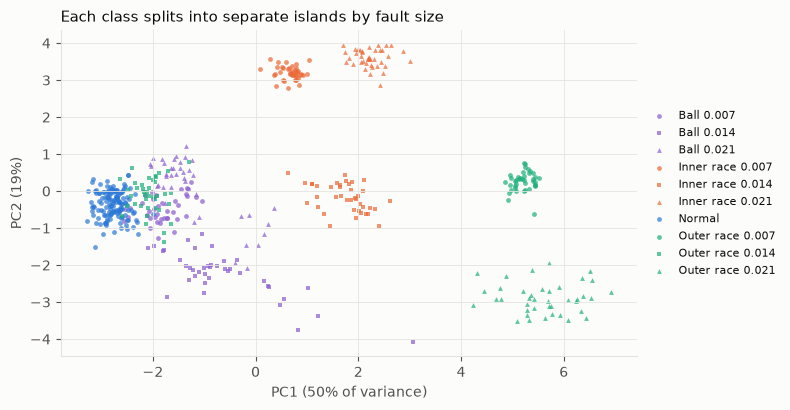

In [16]:
Z = PCA(2, random_state=0).fit(StandardScaler().fit_transform(A))
P = Z.transform(StandardScaler().fit_transform(A))
markers = {0.0: "o", 0.007: "o", 0.014: "s", 0.021: "^"}
fig, a = plt.subplots(figsize=(8, 4.2))
for (label, d), g in meta.groupby(["label", "damage"]):
    a.scatter(P[g.index, 0], P[g.index, 1], s=12, marker=markers[d], color=CLASS_COLORS[label], alpha=0.7, linewidths=0,
              label=f"{label} {d:.3f}" if d else label)
a.set_xlabel(f"PC1 ({Z.explained_variance_ratio_[0]:.0%} of variance)")
a.set_ylabel(f"PC2 ({Z.explained_variance_ratio_[1]:.0%})")
a.legend(frameon=False, fontsize=8, ncol=1, loc="center left", bbox_to_anchor=(1.0, 0.5))
a.set_title("Each class splits into separate islands by fault size")
fig.tight_layout()
plt.show()

Inner race faults and the 0.007 and 0.021 in outer race faults form tight islands far from Normal, but each size sits in its own island. Ball faults and the 0.014 in outer race fault sit next to the healthy cluster, which is the fault with no visible BPFO in §3. A model that never saw a given island has to extrapolate, and for the islands next to Normal there is little to extrapolate from.

---
## 5. What the split does to the score

In my research, CWRU looked saturated under a load-based split, so I wanted to see what a stricter test does. Same data, same model, three ways of building the test set:

| Protocol | Test set | What is shared with training |
|---|---|---|
| **Random windows** | Random 1 s windows, stratified 4-fold | Neighbouring windows of the same recording |
| **Unseen load** | One load held out, 4 folds | The same seeded fault, measured at other loads |
| **Unseen damage** | One fault size held out, plus one healthy load, 12 folds | Only the fault class |

Unseen load matches the simplest round of the benchmark's load-based split. Unseen damage is a stricter test that I added here, because a deployed model meets bearings it has never seen.

Features are compared in three sets: time-domain statistics, envelope physics features, and both. The model is an untuned random forest (300 trees, balanced class weights). These numbers use a subset of CWRU and a random forest, so they are **not comparable** with the deep learning results in my manuscript.

In [17]:
def random_folds(seed):
    return list(StratifiedKFold(4, shuffle=True, random_state=seed).split(time_f, y))

def load_folds():
    return [(np.where(meta["load"] != l)[0], np.where(meta["load"] == l)[0]) for l in range(4)]

def damage_folds():
    folds = []
    for size in (0.007, 0.014, 0.021):
        for l in range(4):
            test = (meta["damage"] == size).values | (is_normal & (meta["load"] == l).values)
            train = ((meta["damage"] != size).values & ~is_normal) | (is_normal & (meta["load"] != l).values)
            folds.append((np.where(train)[0], np.where(test)[0], size, l))
    return folds

assert all(not set(f[0]) & set(f[1]) for f in load_folds() + damage_folds())
ORDER = ["Random windows", "Unseen load", "Unseen damage"]

In [18]:
SEEDS = range(5)
records, confusion = [], {}
for seed in SEEDS:
    protocols = {"Random windows": random_folds(seed), "Unseen load": load_folds(), "Unseen damage": damage_folds()}
    for protocol, folds in protocols.items():
        for feature_name, A in FEATURES.items():
            for fold in folds:
                train, test = fold[0], fold[1]
                model = RandomForestClassifier(300, class_weight="balanced", random_state=seed, n_jobs=-1)
                pred = model.fit(A.iloc[train], y[train]).predict(A.iloc[test])
                recalls = recall_score(y[test], pred, average=None, labels=b.CLASSES, zero_division=0)
                records.append(dict(seed=seed, protocol=protocol, features=feature_name,
                                    size=fold[2] if len(fold) > 2 else None,
                                    balanced_accuracy=balanced_accuracy_score(y[test], pred),
                                    macro_f1=f1_score(y[test], pred, average="macro"),
                                    **dict(zip(b.CLASSES, recalls))))
                key = (protocol, feature_name)
                confusion[key] = confusion.get(key, 0) + confusion_matrix(y[test], pred, labels=b.CLASSES)
results = pd.DataFrame(records)
per_seed = results.groupby(["protocol", "features", "seed"])[["balanced_accuracy", "macro_f1"]].mean()
summary = per_seed.groupby(["protocol", "features"]).agg(
    balanced_accuracy=("balanced_accuracy", "mean"), seed_min=("balanced_accuracy", "min"),
    seed_max=("balanced_accuracy", "max"), macro_f1=("macro_f1", "mean")).round(3)
summary = summary.reindex(ORDER, level=0)
summary.to_csv("results/protocols.csv")
summary

balanced_accuracy  seed_min  seed_max  \
protocol       features                                                  
Random windows Both                          0.992     0.988     0.996   
               Envelope physics              0.964     0.952     0.974   
               Time statistics               0.985     0.981     0.990   
Unseen load    Both                          0.984     0.983     0.985   
               Envelope physics              0.951     0.947     0.958   
               Time statistics               0.954     0.952     0.956   
Unseen damage  Both                          0.713     0.703     0.722   
               Envelope physics              0.631     0.629     0.634   
               Time statistics               0.557     0.554     0.560   

                                 macro_f1  
protocol       features                    
Random windows Both                 0.992  
               Envelope physics     0.964  
               Time statistics      0.985  
Unseen load    Both                 0.984  
               Envelope physics     0.950  
               Time statistics      0.954  
Unseen damage  Both                 0.651  
               Envelope physics     0.571  
               Time statistics      0.466

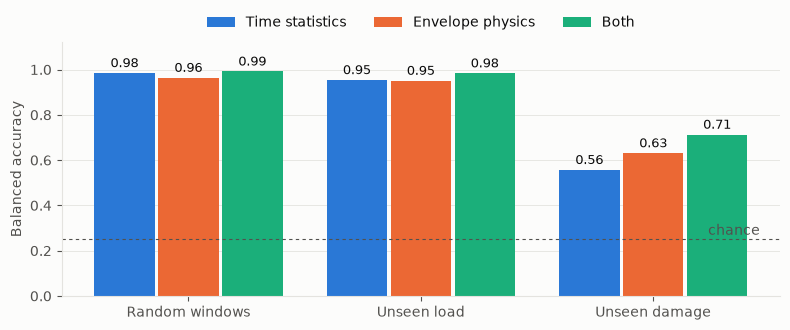

In [19]:
names = list(FEATURES)
values = summary["balanced_accuracy"].unstack().reindex(index=ORDER, columns=names)
fig, a = plt.subplots(figsize=(8, 3.4))
width = 0.26
for i, (name, color) in enumerate(zip(names, (BLUE, ORANGE, AQUA))):
    bars = a.bar(np.arange(3) + (i - 1) * (width + 0.015), values[name], width, color=color, label=name)
    a.bar_label(bars, fmt="%.2f", padding=2, fontsize=9, color=INK)
a.set_xticks(range(3), ORDER); a.set_ylim(0, 1.12); a.set_ylabel("Balanced accuracy")
a.axhline(0.25, color=MUTED, linestyle=(0, (3, 3)), linewidth=0.8); a.text(2.46, 0.27, "chance", color=MUTED, ha="right")
a.legend(frameon=False, ncol=3, loc="lower center", bbox_to_anchor=(0.5, 1.0)); a.grid(axis="x", visible=False); a.set_axisbelow(True)
fig.tight_layout()
plt.show()

In [20]:
by_size = (results[results.protocol == "Unseen damage"]
           .groupby(["features", "size"])[["balanced_accuracy"] + b.CLASSES].mean().round(2))
by_size.to_csv("results/unseen_damage_by_size.csv")
by_size

balanced_accuracy  Normal  Inner race  Outer race  \
features         size                                                       
Both             0.007               0.83    1.00        1.00        0.99   
                 0.014               0.50    1.00        0.00        0.00   
                 0.021               0.81    1.00        1.00        1.00   
Envelope physics 0.007               0.77    0.92        1.00        1.00   
                 0.014               0.38    0.99        0.12        0.00   
                 0.021               0.74    0.87        1.00        1.00   
Time statistics  0.007               0.51    1.00        0.03        0.00   
                 0.014               0.50    1.00        0.00        0.00   
                 0.021               0.66    1.00        0.03        1.00   

                        Ball  
features         size         
Both             0.007  0.34  
                 0.014  1.00  
                 0.021  0.23  
Envelope physics 0.007  0.14  
                 0.014  0.42  
                 0.021  0.10  
Time statistics  0.007  1.00  
                 0.014  1.00  
                 0.021  0.62

In [21]:
matrix = (pd.DataFrame(confusion[("Unseen damage", "Both")], index=b.CLASSES, columns=b.CLASSES) / len(SEEDS)).round(1)
matrix.index.name, matrix.columns.name = "true", "predicted"
matrix

predicted,Normal,Inner race,Outer race,Ball
true,,,,
Normal,420.0,0.0,0.0,0.0
Inner race,0.0,320.0,0.0,160.0
Outer race,3.0,2.0,318.0,157.0
Ball,0.0,9.4,219.0,251.6


The full-feature model only fails where it has to extrapolate to a fault size it has not seen. The next section asks whether that is a property of the random forest or of the data.

---
## 6. Lightweight classifiers across model families

Same 500 windows, same folds and seeds as §5. Seven models, one per family, all small enough to run on an edge gateway:

| Model | Family | Input | Fixed settings |
|---|---|---|---|
| Logistic regression | Linear | 17 features | standardised, C = 1, balanced |
| k-NN | Instance-based | 17 features | standardised, k = 5 |
| SVM (RBF) | Kernel | 17 features | standardised, C = 1, γ = scale, balanced |
| Random forest | Bagged trees | 17 features | 300 trees, balanced (the §5 model) |
| Gradient boosting | Boosted trees | 17 features | sklearn `HistGradientBoosting` defaults, balanced |
| MLP | Neural net | 17 features | 64-32 ReLU, L2 1e-3, early stopping |
| 1D-CNN | Neural net | raw 1 s window | WDCNN-style, ~25 k parameters, 40 epochs, random 4096-sample crops |

Hyperparameters were fixed before running and are **not tuned** on any test fold. The 1D-CNN learns its own features from the raw signal (each window standardised, so absolute level is removed) and is the only model that does not use the envelope physics. It is trained on 3 of the 5 seeds to keep the run time manageable on a laptop CPU.

This cell is the slowest in the notebook (≈ 20 to 25 min on a laptop CPU, mostly the 1D-CNN).

In [22]:
CNN_SEEDS = range(3)
X_feat = FEATURES["Both"].values
model_records, model_confusion, fit_seconds = [], {}, {}
for seed in SEEDS:
    protocols = {"Random windows": random_folds(seed), "Unseen load": load_folds(), "Unseen damage": damage_folds()}
    for protocol, folds in protocols.items():
        for fold in folds:
            train, test = fold[0], fold[1]
            zoo = models.model_zoo(seed)
            if seed in CNN_SEEDS:
                zoo["1D-CNN"] = models.CNNClassifier(b.CLASSES, seed=seed)
            for name, model in zoo.items():
                A_ = X if name == "1D-CNN" else X_feat
                t0 = time.perf_counter()
                model.fit(A_[train], y[train])
                fit_seconds.setdefault(name, []).append(time.perf_counter() - t0)
                pred = model.predict(A_[test])
                recalls = recall_score(y[test], pred, average=None, labels=b.CLASSES, zero_division=0)
                model_records.append(dict(seed=seed, protocol=protocol, model=name,
                                          size=fold[2] if len(fold) > 2 else None,
                                          balanced_accuracy=balanced_accuracy_score(y[test], pred),
                                          macro_f1=f1_score(y[test], pred, average="macro"),
                                          **dict(zip(b.CLASSES, recalls))))
                key = (protocol, name)
                model_confusion[key] = model_confusion.get(key, 0) + confusion_matrix(y[test], pred, labels=b.CLASSES)
model_results = pd.DataFrame(model_records)
MODELS = list(models.FAMILIES)
per_seed = model_results.groupby(["protocol", "model", "seed"])[["balanced_accuracy", "macro_f1"]].mean()
model_summary = per_seed.groupby(["protocol", "model"]).agg(
    balanced_accuracy=("balanced_accuracy", "mean"), seed_min=("balanced_accuracy", "min"),
    seed_max=("balanced_accuracy", "max"), macro_f1=("macro_f1", "mean")).round(3)
model_summary.to_csv("results/model_comparison.csv")
comparison = model_summary["balanced_accuracy"].unstack(0)[ORDER].reindex(MODELS)
comparison.insert(0, "family", [models.FAMILIES[m] for m in comparison.index])
comparison.sort_values("Unseen damage", ascending=False)

protocol,family,Random windows,Unseen load,Unseen damage
model,,,,
Gradient boosting,Boosted trees,0.986,0.946,0.751
Random forest,Bagged trees,0.992,0.984,0.713
k-NN,Instance-based,0.965,0.930,0.671
MLP,Neural net (features),0.902,0.888,0.651
1D-CNN,Neural net (raw signal),1.000,0.986,0.616
Logistic regression,Linear,0.945,0.902,0.581
SVM (RBF),Kernel,0.949,0.907,0.502


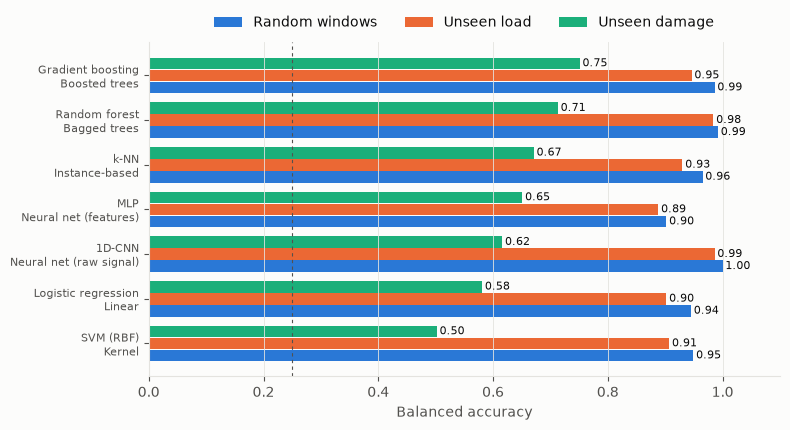

In [23]:
fig, a = plt.subplots(figsize=(8, 4.4))
height = 0.26
ranked = comparison.sort_values("Unseen damage").index
for i, (protocol, color) in enumerate(zip(ORDER, (BLUE, ORANGE, AQUA))):
    v = comparison.loc[ranked, protocol]
    bars = a.barh(np.arange(len(ranked)) + (i - 1) * (height + 0.01), v, height, color=color, label=protocol)
    a.bar_label(bars, fmt="%.2f", padding=2, fontsize=8, color=INK)
a.set_yticks(range(len(ranked)), [f"{m}\n{models.FAMILIES[m]}" for m in ranked], fontsize=8)
a.set_xlim(0, 1.1); a.set_xlabel("Balanced accuracy")
a.axvline(0.25, color=MUTED, linestyle=(0, (3, 3)), linewidth=0.8)
a.legend(frameon=False, ncol=3, loc="lower center", bbox_to_anchor=(0.5, 1.0)); a.grid(axis="y", visible=False)
fig.tight_layout()
plt.show()

- Under **random windows** every model scores 0.90 to 1.00 and the 1D-CNN is perfect. At this level the ranking says little.
- **Unseen load** changes little (0.89 to 0.99): the same seeded defect is still in training, and the 1D-CNN is still first (0.986).
- Under **unseen damage** the spread opens: gradient boosting 0.751, random forest 0.713, k-NN 0.671, MLP 0.651 (seed range 0.60 to 0.74, the least stable model), 1D-CNN 0.616, logistic regression 0.581, SVM 0.502.
- **The ranking flips.** The 1D-CNN goes from first to fifth, and the SVM, at 0.95 on random windows, ends up at the 0.50 that the 0.014 in fold alone forces on everyone. Choosing a model on a random split would pick the wrong one.

### Where each model fails under unseen damage

Recall per class (columns) and balanced accuracy per held-out fault size, averaged over seeds and folds.

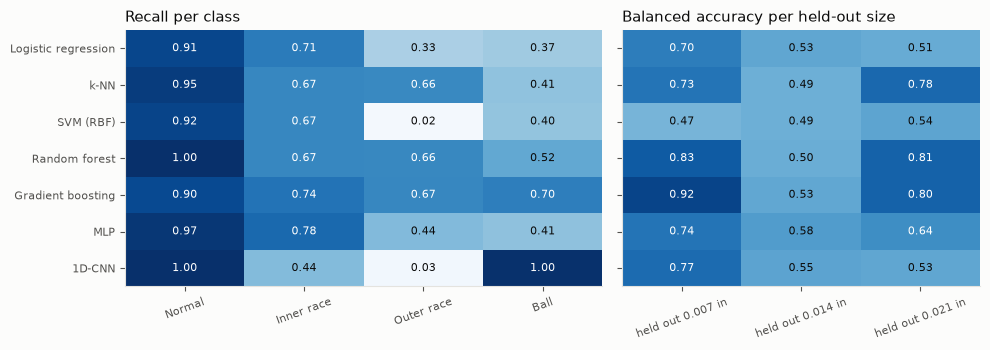

In [24]:
damage = model_results[model_results.protocol == "Unseen damage"]
recall_table = damage.groupby("model")[b.CLASSES].mean().reindex(MODELS)
size_table = damage.pivot_table(index="model", columns="size", values="balanced_accuracy", aggfunc="mean").reindex(MODELS)
size_table.columns = [f"held out {c:.3f} in" for c in size_table.columns]

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), gridspec_kw=dict(width_ratios=(4, 3)))
for a, table, title in ((axes[0], recall_table, "Recall per class"), (axes[1], size_table, "Balanced accuracy per held-out size")):
    a.imshow(table.values, cmap="Blues", vmin=0, vmax=1, aspect="auto")
    for (r, c), v in np.ndenumerate(table.values):
        a.text(c, r, f"{v:.2f}", ha="center", va="center", fontsize=8, color="white" if v > 0.6 else INK)
    a.set_xticks(range(table.shape[1]), table.columns, fontsize=8, rotation=20)
    a.set_yticks(range(len(table)), table.index if a is axes[0] else [""] * len(table), fontsize=8)
    a.grid(False); a.set_title(title)
fig.tight_layout()
plt.show()

- **Holding out 0.014 in puts every model at 0.49 to 0.58.** Seven different families fail the same way, so this is a property of the data (the 0.014 in outer race fault has no visible signature), not of a model.
- The families differ at 0.007 and 0.021 in. **Gradient boosting is the only model that recovers ball faults** (recall 0.70 vs 0.52 at most for the other feature models) and reaches 0.92 when 0.007 in is held out.
- The **1D-CNN labels almost every unseen outer race fault as a ball fault** (outer race recall 0.03, ball 1.00). It learned waveform shapes that tell the training recordings apart but do not carry over to a new fault size. The SVM loses the outer race in the same way (0.02).
- Gradient boosting pays for its ball recall with false alarms: it calls some healthy windows outer race (Normal recall 0.90), while the random forest and the CNN never do.

In [25]:
best = comparison["Unseen damage"].idxmax()
matrix = (pd.DataFrame(model_confusion[("Unseen damage", best)], index=b.CLASSES, columns=b.CLASSES)
          / (len(CNN_SEEDS) if best == "1D-CNN" else len(SEEDS))).round(1)
matrix.index.name, matrix.columns.name = "true", "predicted"
print(f"Best model under unseen damage: {best}. Confusion matrix summed over the 12 folds, averaged over seeds.")
matrix

Best model under unseen damage: Gradient boosting. Confusion matrix summed over the 12 folds, averaged over seeds.


predicted,Normal,Inner race,Outer race,Ball
true,,,,
Normal,396.0,0.0,24.0,0.0
Inner race,0.0,356.0,107.0,17.0
Outer race,8.0,0.0,320.0,152.0
Ball,1.0,48.0,97.0,334.0


### What it costs to deploy

Each model is refit once on all 500 windows. *Parameters* counts the numbers the model stores (weights, tree nodes, support vectors, or stored training points for k-NN). *Latency* is the median time to classify a single window on this laptop's CPU, one window at a time; the end-to-end figure adds feature extraction (time statistics + envelope spectrum) for the feature-based models, so they can be compared fairly with the CNN, which reads the raw window.

In [26]:
def window_features(x, hz):
    return np.array([[*b.time_features(x).values(), *b.physics_features(x, hz).values()]])

sample = np.random.default_rng(0).choice(len(X), 50, replace=False)
feature_ms = models.latency_ms(lambda x: window_features(x[0], b.SHAFT_HZ[0]), X[sample], repeat=1)
zoo = models.model_zoo(0) | {"1D-CNN": models.CNNClassifier(b.CLASSES, seed=0)}
rows = []
for name, model in zoo.items():
    A_ = X if name == "1D-CNN" else X_feat
    model.fit(A_, y)
    if name == "Random forest":
        model.set_params(n_jobs=1)  # a thread pool per single-window call would only measure overhead
    ms = models.latency_ms(model.predict, A_[sample])
    rows.append(dict(model=name, family=models.FAMILIES[name], parameters=models.n_parameters(model),
                     size_kB=models.size_kb(model), train_s=np.median(fit_seconds[name]),
                     model_ms=ms, end_to_end_ms=ms + (0 if name == "1D-CNN" else feature_ms)))
cost = pd.DataFrame(rows).set_index("model").reindex(MODELS)
cost["unseen damage"] = comparison["Unseen damage"]
cost.round(3).to_csv("results/model_cost.csv")
print(f"Feature extraction alone: {feature_ms:.2f} ms per window")
cost.round({"size_kB": 1, "train_s": 2, "model_ms": 2, "end_to_end_ms": 2, "unseen damage": 3})

Feature extraction alone: 2.91 ms per window


,family,parameters,size_kB,train_s,model_ms,end_to_end_ms,unseen damage
model,,,,,,,
Logistic regression,Linear,72,2.1,0.01,0.20,3.11,0.581
k-NN,Instance-based,8500,71.8,0.00,0.38,3.30,0.671
SVM (RBF),Kernel,3320,28.7,0.00,0.21,3.12,0.502
Random forest,Bagged trees,6790,735.8,0.33,12.25,15.17,0.713
Gradient boosting,Boosted trees,8702,564.9,1.63,27.73,30.64,0.751
MLP,Neural net (features),3364,89.0,0.11,0.23,3.14,0.651
1D-CNN,Neural net (raw signal),24948,99.1,16.96,1.86,1.86,0.616


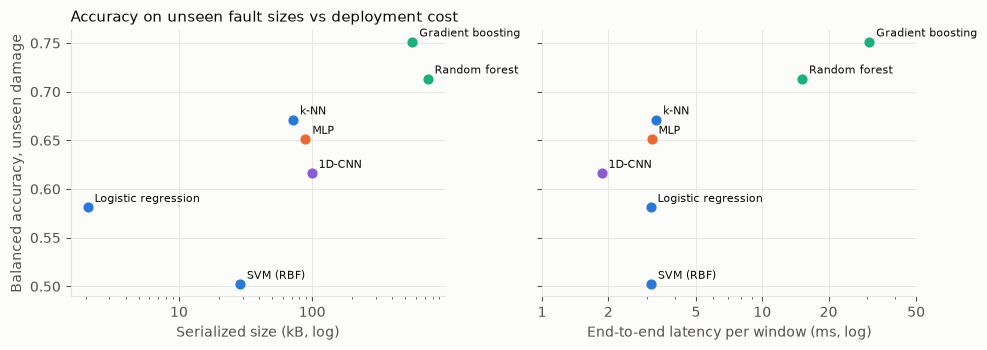

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for a, col, label in ((axes[0], "size_kB", "Serialized size (kB, log)"), (axes[1], "end_to_end_ms", "End-to-end latency per window (ms, log)")):
    for name, r in cost.iterrows():
        color = PURPLE if name == "1D-CNN" else (AQUA if "trees" in r.family else (ORANGE if "Neural" in r.family else BLUE))
        a.scatter(r[col], r["unseen damage"], s=40, color=color, zorder=3)
        a.annotate(name, (r[col], r["unseen damage"]), xytext=(5, 4), textcoords="offset points", fontsize=8, color=INK)
    a.set_xscale("log"); a.set_xlabel(label)
    a.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}"))
    a.xaxis.set_minor_formatter(plt.NullFormatter())
axes[1].set_xticks([1, 2, 5, 10, 20, 50])
axes[0].set_ylabel("Balanced accuracy, unseen damage")
axes[0].set_title("Accuracy on unseen fault sizes vs deployment cost")
fig.tight_layout()
plt.show()

- **Every model is small.** The largest, the random forest, pickles to 736 kB, and the 1D-CNN holds 25 k float32 weights (99 kB).
- **Feature extraction dominates the latency of the feature models** (about 3 ms per window: band-pass, Hilbert, two FFTs). The classifiers themselves take 0.2 to 0.4 ms. The tree ensembles take 12 to 28 ms, but that is per-call Python overhead in scikit-learn, not arithmetic: about 9 k tree nodes evaluate in microseconds once exported to compiled code or ONNX.
- **The 1D-CNN is the fastest end to end** (1.9 ms, no feature extraction) and **the slowest to train** (17 s per fold against at most 1.6 s for the others).
- On the accuracy vs cost plane there is no free lunch: the two models with the best unseen-damage score are the two largest.

### Which features carry generalisation?

Grouped permutation importance of the best tree model on the **test** folds: how much balanced accuracy drops when a whole group of features is shuffled together. Groups are used because features inside a group are nearly redundant (RMS, standard deviation and peak are almost the same number), and shuffling one of them alone hides its importance behind the others. Comparing a random split with unseen damage shows what the model leans on when it can memorise recordings, and what still helps on a new fault size.

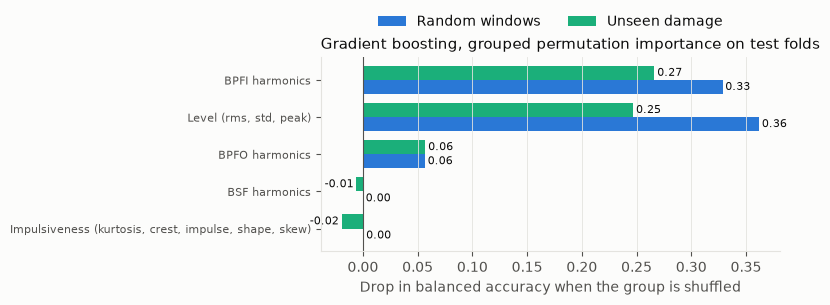

,Random windows,Unseen damage
"Level (rms, std, peak)",0.362,0.247
"Impulsiveness (kurtosis, crest, impulse, shape, skew)",0.000,-0.019
BPFO harmonics,0.057,0.057
BPFI harmonics,0.329,0.266
BSF harmonics,0.000,-0.006


In [28]:
GROUPS = {
    "Level (rms, std, peak)": ["rms", "std", "peak"],
    "Impulsiveness (kurtosis, crest, impulse, shape, skew)": ["kurtosis", "crest", "impulse", "shape", "skew"],
    "BPFO harmonics": [f"BPFO_h{h}" for h in (1, 2, 3)],
    "BPFI harmonics": [f"BPFI_h{h}" for h in (1, 2, 3)],
    "BSF harmonics": [f"BSF_h{h}" for h in (1, 2, 3)],
}
tree_name = comparison.loc[["Random forest", "Gradient boosting"], "Unseen damage"].idxmax()
columns = list(FEATURES["Both"].columns)

def grouped_importance(folds, seed=0, repeats=5):
    rng = np.random.default_rng(seed)
    drops = {g: [] for g in GROUPS}
    for fold in folds:
        train, test = fold[0], fold[1]
        model = models.model_zoo(seed)[tree_name].fit(X_feat[train], y[train])
        base = balanced_accuracy_score(y[test], model.predict(X_feat[test]))
        for g, cols in GROUPS.items():
            idx = [columns.index(c) for c in cols]
            for _ in range(repeats):
                Xp = X_feat[test].copy()
                Xp[:, idx] = Xp[rng.permutation(len(test))][:, idx]
                drops[g].append(base - balanced_accuracy_score(y[test], model.predict(Xp)))
    return pd.Series({g: np.mean(v) for g, v in drops.items()})

importance = pd.DataFrame({"Random windows": grouped_importance(random_folds(0)),
                           "Unseen damage": grouped_importance(damage_folds())})
fig, a = plt.subplots(figsize=(8, 3.2))
top = importance.sort_values("Unseen damage")
for i, (col, color) in enumerate(zip(importance.columns, (BLUE, AQUA))):
    bars = a.barh(np.arange(len(top)) + (i - 0.5) * 0.38, top[col], 0.38, color=color, label=col)
    a.bar_label(bars, fmt="%.2f", padding=2, fontsize=8, color=INK)
a.set_yticks(range(len(top)), top.index, fontsize=8); a.axvline(0, color=MUTED, linewidth=0.8)
a.set_xlabel("Drop in balanced accuracy when the group is shuffled"); a.grid(axis="y", visible=False)
a.set_title(f"{tree_name}, grouped permutation importance on test folds")
a.legend(frameon=False, ncol=2, loc="lower center", bbox_to_anchor=(0.5, 1.08))
fig.tight_layout()
plt.show()
importance.round(3)

Gradient boosting relies on two groups under both protocols: **BPFI harmonics** (0.33 → 0.27) and **level** (0.36 → 0.25). Shuffling the impulsiveness or BSF groups changes nothing, or slightly helps under unseen damage, so those features add noise rather than information on new fault sizes. Level stays important even though §4 shows it is largely a recording fingerprint: in this dataset level still separates healthy from faulty windows, because there is a single healthy bearing. On a fleet of machines, where absolute level depends on mounting and machine size, that dependence is the first thing I would expect to break.

---
## 7. Conclusions and limitations

### Q1. Can classical processing recover the fault frequency?

- **Yes, where the fault is physically visible.** With the measured speed, the envelope peak lands within 0.5 Hz of the geometric BPFI in every inner race recording, and within ~0.3 Hz of BPFO for the clear outer race fault.
- **Measured speed matters.** It halves the worst frequency error (1.21 → 0.49 Hz) and, used in the envelope features, raises the envelope-physics random forest under unseen load from 0.926 (nominal speed, previous version of this notebook) to 0.951.
- **Not every fault has a signature.** Ball faults are weak at every size and the 0.014 in outer race fault has almost no BPFO (peak-to-floor ratio 5.9, against 146 to 777 at the other sizes), in line with Smith and Randall (2015).

### Q2. What does the split do to the score?

- **Holding out a load barely moves the score; holding out a fault size does** (random forest, both feature sets: 0.992 → 0.984 → 0.713). The same seeded fault stays in training under other loads, which is consistent with CWRU looking saturated under load-based splits. I treat it as a hypothesis, not a proven cause.
- **The feature ranking flips with the protocol.** Time statistics beat envelope physics under random splits (0.985 vs 0.964) and lose under unseen damage (0.557 vs 0.631). The η² analysis explains why: time statistics, especially kurtosis, crest and impulse factor, identify the recording far better than the class.
- **Part of the drop is the data, not the model.** The 0.014 in fold stays at about 0.5 for every model and feature set. For the outer race the signature is nearly absent; for the inner race the peak is visible at file level, so that miss is still unexplained.

### Q3. Which lightweight model family generalises best?

- **Model ranking, like feature ranking, depends on the protocol.** The 1D-CNN is first under random windows and unseen load and fifth under unseen damage. The SVM goes from 0.95 to 0.50.
- **Tree ensembles generalise best to unseen fault sizes**: gradient boosting 0.751, random forest 0.713, then k-NN 0.671, MLP 0.651, 1D-CNN 0.616, logistic regression 0.581, SVM 0.502. Gradient boosting is the only model that recovers ball faults.
- **Learning features from the raw signal does not help here.** With 40 recordings, the CNN learns what tells the recordings apart. It might pay off with many more bearings, or with augmentation that varies level and resonance.

**Recommendation for a lightweight deployable classifier:** gradient boosting on the 17 time and envelope features. It has the best unseen-damage score, needs about 3 ms of feature extraction per 1 s window, and is under 600 kB (much less as compiled code). If memory is the binding constraint (a microcontroller), the MLP (89 kB) or logistic regression (2 kB) on the same features cost 0.10 to 0.17 balanced accuracy on unseen sizes. In every case the envelope features need the shaft speed, so a tachometer or speed estimate is part of the model.

### Limitations

- One dataset, one test rig, one healthy bearing, seeded (not naturally grown) faults.
- Untuned models with fixed hyperparameters, a fixed 2 to 5.5 kHz demodulation band, and a 1D-CNN trained on 3 of 5 seeds with a fixed number of epochs.
- Windows are not independent, so the seed range shows model variability and says little about data uncertainty. Several models are deterministic given the folds, so their seed range is zero outside the random split.
- Latency is measured in Python on a laptop CPU, one window at a time, not on target hardware.

### Next steps

- Repeat the unseen-damage protocol on datasets with more bearings per class (Paderborn, IMS) to test whether the tree-ensemble advantage holds.
- Pick the demodulation band per window with a fast kurtogram instead of a fixed band, and use order tracking in place of a single speed per recording.
- Add the fan-end channel and the 48 kHz data, and test a CNN with level and resonance augmentation.
